1. Implement the **histogram equalization algorithm** and apply it to the test images show below. Show the histogram **before** and **after** the histogram equalization.

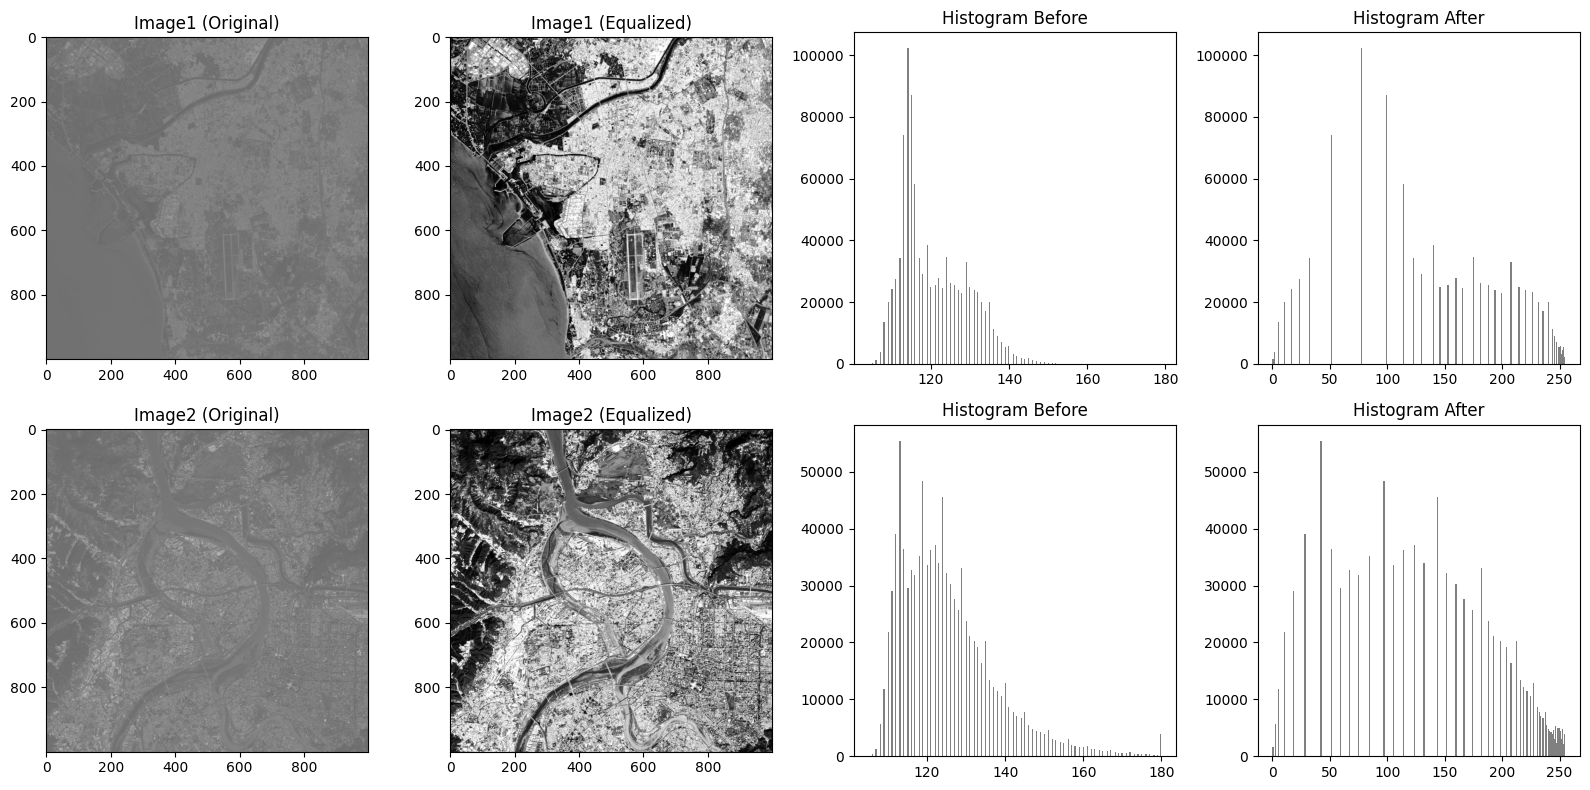

In [2]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

image1 = cv2.imread("./image/Histogram equalization_Test1.bmp", cv2.IMREAD_GRAYSCALE)
image2 = cv2.imread("./image/Histogram equalization_Test2.bmp", cv2.IMREAD_GRAYSCALE)

def hist_equalize_gray(img):
    hist = np.bincount(img.flatten(), minlength=256)
    pdf = hist / img.size
    cdf = np.cumsum(pdf)
    cdf_norm = (cdf - cdf.min()) / (cdf.max() - cdf.min()) # Normalize to [0,1]
    mapping = np.round(255 * cdf_norm).astype(np.uint8) # Scale to [0,255]
    return mapping[img]

eq1 = hist_equalize_gray(image1)
eq2 = hist_equalize_gray(image2)
# eq1 = cv2.equalizeHist(image1)
# eq2 = cv2.equalizeHist(image2)

fig, ax_arr = plt.subplots(2, 4, figsize=(16, 8))

ax_arr[0,0].imshow(image1, cmap='gray', vmin=0, vmax=255) # Display image with original range
ax_arr[0,0].set_title("Image1 (Original)")
ax_arr[0,1].imshow(eq1, cmap='gray', vmin=0, vmax=255)
ax_arr[0,1].set_title("Image1 (Equalized)")
ax_arr[0,2].hist(image1.flatten(), bins=256, color='gray')
ax_arr[0,2].set_title("Histogram Before")
ax_arr[0,3].hist(eq1.flatten(), bins=256, color='gray')
ax_arr[0,3].set_title("Histogram After")

ax_arr[1,0].imshow(image2, cmap='gray', vmin=0, vmax=255)
ax_arr[1,0].set_title("Image2 (Original)")
ax_arr[1,1].imshow(eq2, cmap='gray', vmin=0, vmax=255)
ax_arr[1,1].set_title("Image2 (Equalized)")
ax_arr[1,2].hist(image2.flatten(), bins=256, color='gray')
ax_arr[1,2].set_title("Histogram Before")
ax_arr[1,3].hist(eq2.flatten(), bins=256, color='gray')
ax_arr[1,3].set_title("Histogram After")

plt.tight_layout()
plt.show()


3. Implement the **histogram matching algorithm** and use this algorithm to balancing the colors of the tested images.

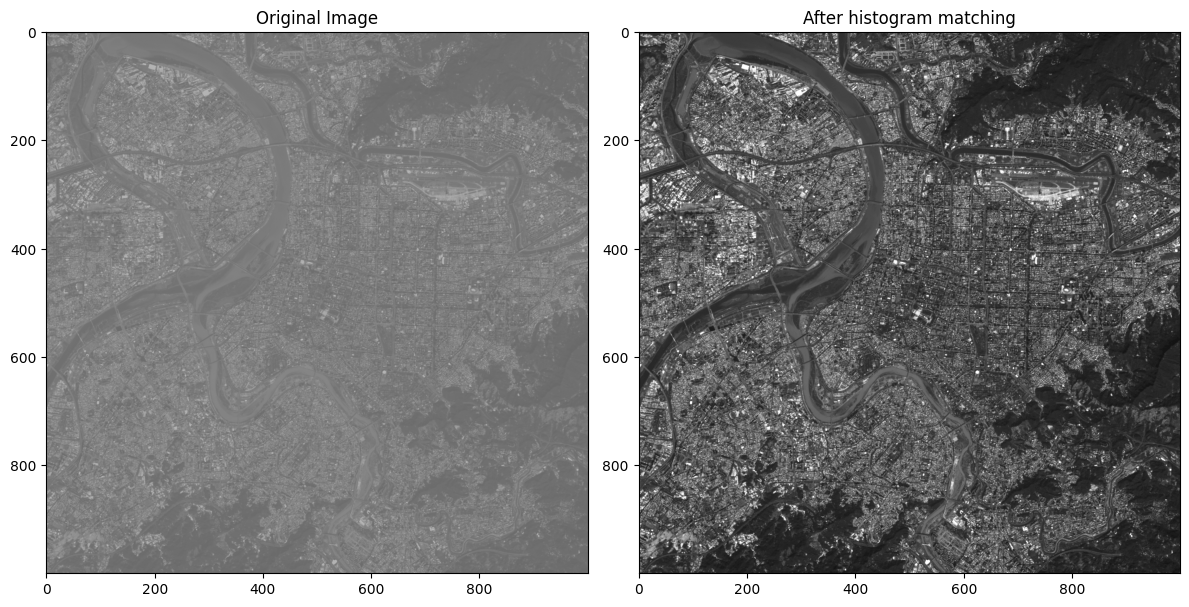

In [4]:
# from skimage import exposure

image1 = cv2.imread("./image/Histogram Matching Test1/Taipei_1000x1000_01.bmp", cv2.IMREAD_GRAYSCALE)
image2 = cv2.imread("./image/Histogram Matching Test1/Taipei_1000x1000_02_LowConstrast.bmp", cv2.IMREAD_GRAYSCALE)

def histogram_match_gray(src, ref):
    hist_src, _ = np.histogram(src.flatten(), bins=256, range=(0, 256))
    hist_ref, _ = np.histogram(ref.flatten(), bins=256, range=(0, 256))
    cdf_src = np.cumsum(hist_src).astype(np.float64)
    cdf_ref = np.cumsum(hist_ref).astype(np.float64)
    cdf_src = cdf_src / cdf_src[-1] # Normalize to [0,1]
    cdf_ref = cdf_ref / cdf_ref[-1]
    mapping = np.interp(cdf_src, cdf_ref, np.arange(256)) # Map src to ref
    mapping = np.clip(np.round(mapping), 0, 255).astype(np.uint8) # Ensure valid range
    return mapping[src]

matched = histogram_match_gray(image2, image1)
# matched_skimg = exposure.match_histograms(image2, image1)
# diff = cv2.absdiff(matched, matched_skimg.astype(np.uint8))
# print(diff.mean())

fig, ax_arr = plt.subplots(1, 2, figsize=(12, 6))
ax_arr[0].imshow(image2, cmap='gray', vmin=0, vmax=255)
ax_arr[0].set_title("Original Image")
ax_arr[1].imshow(matched, cmap='gray', vmin=0, vmax=255)
ax_arr[1].set_title("After histogram matching")

plt.tight_layout()
plt.show()

4. Implement average filter and Sobel filter **without the use of high-level library functions**. Purpose: understand the detailed processes of spatial filtering.

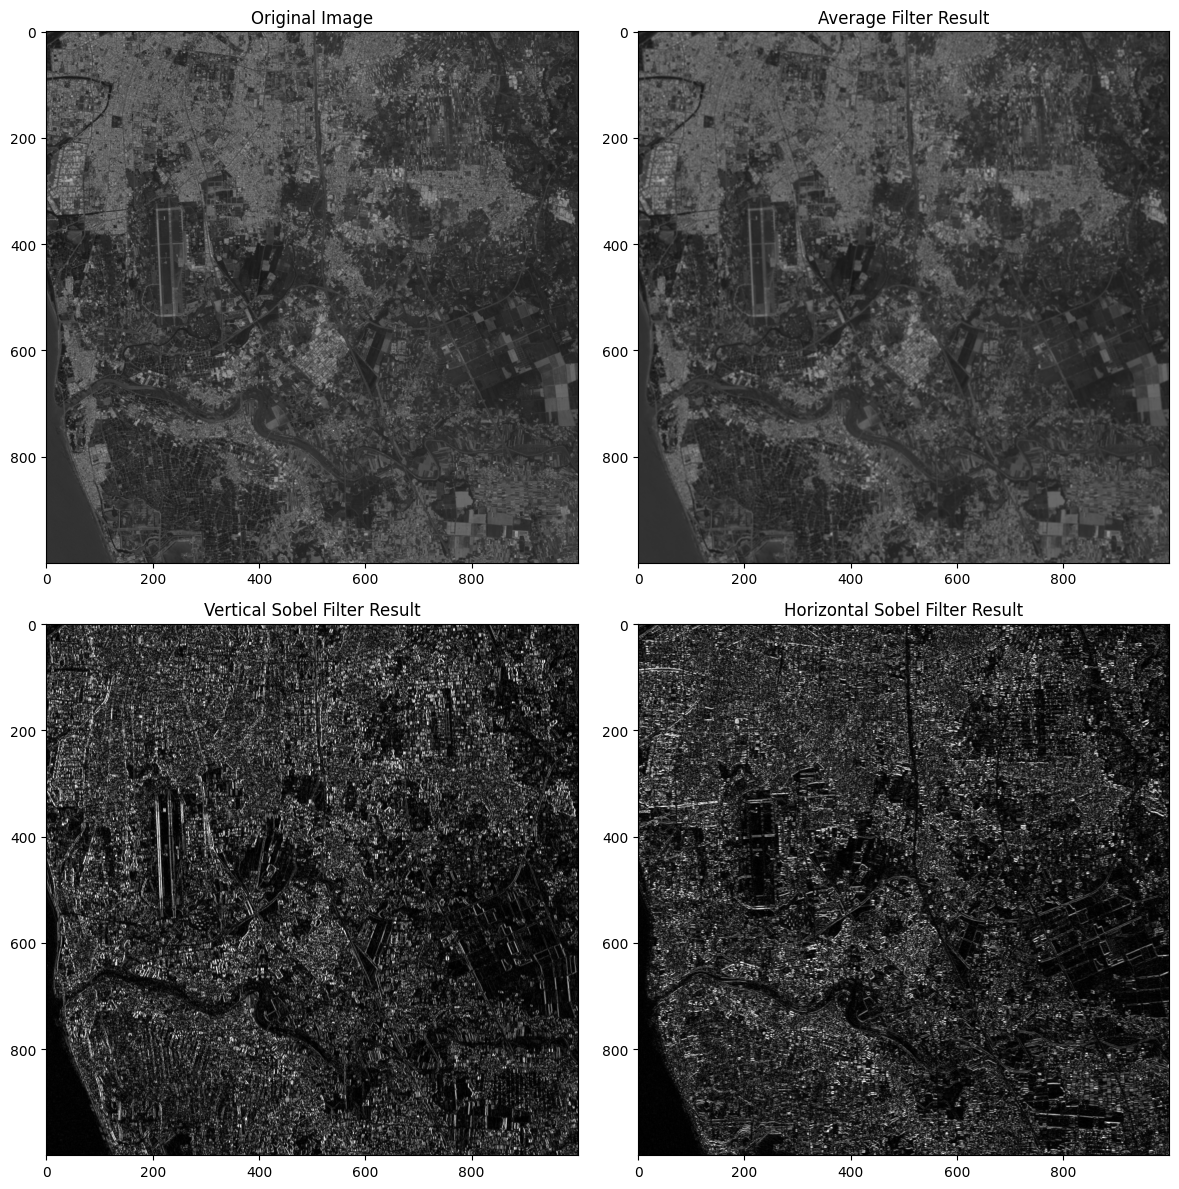

In [10]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

def make_filter(ftype, direction=None):
    if ftype == 'average':
        kernel = np.ones((3, 3)) / 9
    elif ftype == 'sobel':
        if direction == 'vertical':
            kernel = np.array([[-1,  0,  1],
                               [-2,  0,  2],
                               [-1,  0,  1]])
        elif direction == 'horizontal':
            kernel = np.array([[-1, -2, -1],
                               [ 0,  0,  0],
                               [ 1,  2,  1]])
    return kernel

def Conv2D(image, kernel):
    (h, w) = image.shape
    (fh, fw) = kernel.shape
    pad_h, pad_w = fh // 2, fw // 2
    padded_image = np.pad(image, ((pad_h, pad_h), (pad_w, pad_w)), mode='edge')
    output = np.zeros_like(image, dtype=float)
    for i in range(h):
        for j in range(w):
            region = padded_image[i:i+fh, j:j+fw]
            output[i, j] = np.sum(region * kernel)
    output = np.abs(output)
    output = np.clip(output, 0, 255)
    return output.astype(np.uint8)

image = cv2.imread("./image/Histogram Matching Test2/Tainan_1000x1000_02.bmp", cv2.IMREAD_GRAYSCALE)
average_filter = make_filter('average')
vertical_sobel_filter = make_filter('sobel', 'vertical')
horizontal_sobel_filter = make_filter('sobel', 'horizontal')
average_result = Conv2D(image, average_filter)
vertical_sobel_result = Conv2D(image, vertical_sobel_filter)
horizontal_sobel_result = Conv2D(image, horizontal_sobel_filter)

fig, ax_arr = plt.subplots(2, 2, figsize=(12, 12))
ax_arr[0,0].imshow(image, cmap='gray', vmin=0, vmax=255)
ax_arr[0,0].set_title("Original Image")
ax_arr[0,1].imshow(average_result, cmap='gray', vmin=0, vmax=255)
ax_arr[0,1].set_title("Average Filter Result")
ax_arr[1,0].imshow(vertical_sobel_result, cmap='gray', vmin=0, vmax=255)
ax_arr[1,0].set_title("Vertical Sobel Filter Result")
ax_arr[1,1].imshow(horizontal_sobel_result, cmap='gray', vmin=0, vmax=255)
ax_arr[1,1].set_title("Horizontal Sobel Filter Result")
plt.tight_layout()
plt.show()
